# Praktikum 2 - Klasifikasi SVM dengan Data Dummy Non-Linier

Praktikum ini menggunakan data dua kelas berbentuk lingkaran konsentris. Data seperti ini tidak dapat dipisahkan dengan garis lurus, sehingga dibutuhkan **kernel trick**. SVM dengan kernel RBF memetakan data ke ruang berdimensi lebih tinggi agar dapat dipisahkan secara linear.

## Langkah 1a - Import Library

In [8]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

## Langkah 1b - Buat Kembali Fungsi Plotting

In [9]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## Langkah 1c - Buat Data Dummy Non-Linier

Data dibuat dengan `make_circles`: satu kelas berada di lingkaran dalam, kelas lain di lingkaran luar.

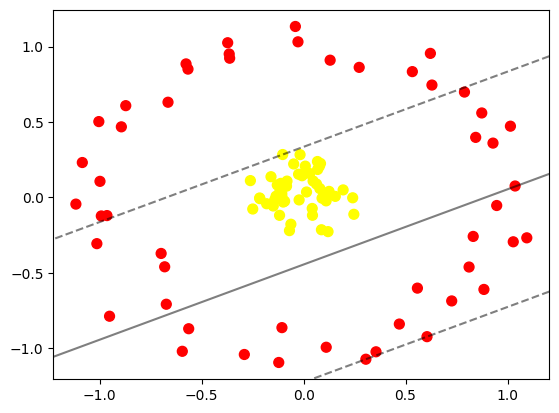

In [10]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles

X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.show()

## Proyeksi Radial

Agar data dapat dipisahkan, ditambahkan satu dimensi baru berbasis jarak radial dari pusat:

$$r = \exp\left(-\sum X^2\right)$$

Dengan dimensi tambahan ini, data diproyeksikan ke ruang 3D.

In [11]:
# proyeksi radial
r = np.exp(-(X**2).sum(1))

## Visualisasi 3D

Cell berikut memakai `ipywidgets` untuk mengubah sudut pandang. Jika berjalan di Google Colab, pastikan modul `ipywidgets` sudah tersedia.

In [ ]:
# !pip install -q ipywidgets
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-1.00385627e+00,  5.02491108e-01],
       [ 8.30028806e-02,  2.24747124e-01],
       [-1.06642317e-01,  2.46528130e-02],
       [ 8.84305596e-01, -6.09954270e-01],
       [-8.35969622e-02,  7.45509013e-02],
       [-2.44445394e-02,  1.53682930e-01],
       [ 8.42363851e-03,  2.07233452e-01],
       [-5.66732476e-01,  8.50281870e-01],
       [-8.13352774e-02,  1.08064403e-01],
       [ 1.09454146e+00, -2.67920861e-01],
       [ 1.11025539e-01, -9.93103143e-01],
       [-1.16439466e-01,  3.64148479e-02],
       [-5.63187937e-01, -8.70364281e-01],
       [-2.60765737e-01,  1.11281763e-01],
       [ 5.33318342e-01,  8.33656774e-01],
       [ 2.46543824e-01, -1.11994913e-01],
       [-2.49144586e-01, -7.69156238e-02],
       [ 1.25000993e-01,  3.98402016e-02],
       [ 1.30263049e-01,  9.09455095e-01],
       [-1.34889110e-01,  8.00461539e-03],
       [-8.71820404e-01,  6.08079054e-01],
       [ 1.02420959e-01, -7.17070176e-04],
       

## Langkah 2 - Fitting Model

Proyeksi eksplisit ke dimensi tinggi membutuhkan komputasi besar. Kernel RBF menyelesaikan hal yang sama tanpa menghitung koordinat baru secara langsung.

In [13]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

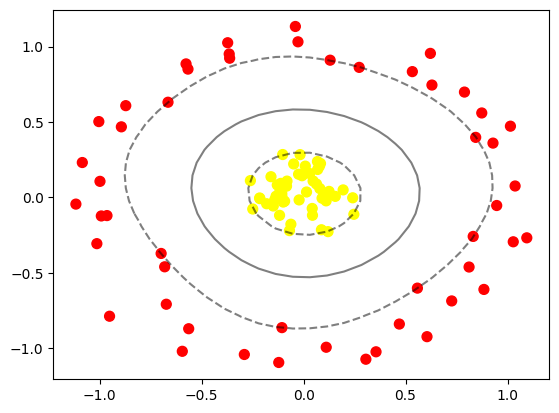

In [14]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')
plt.show()